## DP1 ECDFS photometry diagnostics — correlated-noise-corrected catalogue

This notebook validates the photometric properties of the LSST–VISTA Fusion DP1 ECDFS products using **`full_reduced_cat_DP1_20261029.fits`**. The optical bands are ComCam `u, g, r, i, z, y` and the near-infrared bands are VIRCAM `Z, Y, J, H, K`. The VIDEO DR5 public catalogue provides the independent near-infrared reference.

The analysis uses **forced 6-pixel-radius circular-aperture photometry** consistently across bands. The VIRCAM aperture uncertainties incorporate empirical, band-dependent corrections for correlated blank-sky noise. No fluxes or magnitudes are recalibrated. Per-band source-quality selections require a valid aperture measurement, clean selected pixel flags and **S/N ≥ 5**; a source can be valid in one band without being valid in every band.

The scientific checks cover band completeness, VIDEO residuals, cross-match sensitivity, stellar consistency, VIDEO aperture choice, magnitude distributions and optical–near-infrared colour diagnostics. All figures and statistics are derived from the corrected catalogue. The separate calibration analysis documents how the aperture-noise factors were determined.

### 1. Input catalogues, configuration and paths

The corrected reduced catalogue and VIDEO DR5 reference are loaded once. Plot files are written to a dedicated directory so that these results remain separate from other diagnostics.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import astropy.units as u
from astropy.table import Table
from astropy.coordinates import SkyCoord, match_coordinates_sky
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patheffects as pe

DATA_DIR = Path("../data")

DP1_PATH   = DATA_DIR / "full_reduced_cat_DP1_20261029.fits"
VIDEO_PATH = DATA_DIR / "VISTA-VIDEO-CDFS-DR5.fits"

OUTDIR = Path("data/plots_photometry_corrnoise")
OUTDIR.mkdir(parents=True, exist_ok=True)

# Photometric selection
MAGERR_5SIG = 2.5 / np.log(10) / 5.0
MAGERR_3SIG = 2.5 / np.log(10) / 3.0

MATCH_RADIUS = 0.5 * u.arcsec
VIDEO_APER = 2

SAVE_FIGURES = True

assert DP1_PATH.is_file(), f"Missing DP1 catalogue: {DP1_PATH}"
assert VIDEO_PATH.is_file(), f"Missing VIDEO catalogue: {VIDEO_PATH}"

dp1 = Table.read(DP1_PATH)
vid = Table.read(VIDEO_PATH)

print("DP1 rows :", len(dp1))
print("VIDEO rows:", len(vid))
print("DP1 columns:", len(dp1.colnames))
print("VIDEO columns:", len(vid.colnames))
print("Output directory:", OUTDIR)

DP1 rows : 1477389
VIDEO rows: 1138485
DP1 columns: 274
VIDEO columns: 389
Output directory: data/plots_photometry_corrnoise


### 2. Column definitions and photometric-quality selection

The same selection is applied independently to each band: finite aperture flux and magnitude, positive finite flux uncertainty, an unset aperture-photometry flag, no selected severe pixel-quality flags and forced-aperture **S/N ≥ 5**. Missing band coverage is not treated as a reason to reject a source from unrelated bands.

The quality functions are shared by the residual and colour analyses; the aperture radius is fixed at 6 pixels.

In [2]:
DP1_PREFIX = {
    "u": "ComCam_u_f",
    "g": "ComCam_g_f",
    "r": "ComCam_r_f",
    "i": "ComCam_i_f",
    "z": "ComCam_z_f",
    "y": "ComCam_y_f",
    "Z": "VIRCAM_Z_f",
    "Y": "VIRCAM_Y_f",
    "J": "VIRCAM_J_f",
    "H": "VIRCAM_H_f",
    "K": "VIRCAM_K_f",
}

VIDEO_PREFIX = {
    "Z": "Z",
    "Y": "Y",
    "J": "J",
    "H": "H",
    "K": "KS",
}

APER = "base_CircularApertureFlux_6_0"


# Severe pixel-quality conditions that make the forced measurement
# unsuitable for the clean photometric samples used here.
BAD_PIXEL_FLAGS = [
    "offimage",
    "edgeCenterAll",
    "nodataCenterAll",
    "interpolatedCenterAll",
    "saturatedCenterAll",
    "crCenterAll",
    "badCenterAll",
    "clippedCenterAll",
    "rejectedCenterAll",
]


def has_col(tab, col):
    return col in tab.colnames


def arr(tab, col, dtype=float):
    if col not in tab.colnames:
        raise KeyError(f"Missing column: {col}")

    return np.asarray(
        np.ma.filled(tab[col], np.nan if dtype is float else True),
        dtype=dtype,
    )


def dp1_cols(band):
    prefix = DP1_PREFIX[band]

    return {
        "mag": f"{prefix}_{APER}_mag",
        "magErr": f"{prefix}_{APER}_magErr",
        "flux": f"{prefix}_{APER}_flux",
        "fluxErr": f"{prefix}_{APER}_fluxErr",
        "flag": f"{prefix}_{APER}_flag",
        "pixel_flags": {
            name: f"{prefix}_base_PixelFlags_flag_{name}"
            for name in BAD_PIXEL_FLAGS
        },
    }


def dp1_mag(tab, band):
    return arr(tab, dp1_cols(band)["mag"], float)


def dp1_err(tab, band):
    return arr(tab, dp1_cols(band)["magErr"], float)


def dp1_flux(tab, band):
    return arr(tab, dp1_cols(band)["flux"], float)


def dp1_flux_err(tab, band):
    return arr(tab, dp1_cols(band)["fluxErr"], float)


def dp1_flag(tab, band):
    return arr(
        tab,
        dp1_cols(band)["flag"],
        bool,
    )


def dp1_bad_pixel(tab, band):

    bad = np.zeros(len(tab), dtype=bool)

    for col in dp1_cols(band)["pixel_flags"].values():
        bad |= arr(tab, col, bool)

    return bad


def dp1_snr(tab, band):

    flux = dp1_flux(tab, band)
    flux_err = dp1_flux_err(tab, band)

    snr = np.full(len(tab), np.nan)

    good = (
        np.isfinite(flux)
        & np.isfinite(flux_err)
        & (flux_err > 0)
    )

    snr[good] = flux[good] / flux_err[good]

    return snr


def dp1_band_usable(tab, band, snr_min=5.0):

    mag = dp1_mag(tab, band)
    flux = dp1_flux(tab, band)
    flux_err = dp1_flux_err(tab, band)

    aperture_flag = dp1_flag(tab, band)
    bad_pixel = dp1_bad_pixel(tab, band)

    snr = dp1_snr(tab, band)

    return (
        np.isfinite(mag)
        & np.isfinite(flux)
        & np.isfinite(flux_err)
        & (flux_err > 0)
        & (~aperture_flag)
        & (~bad_pixel)
        & (snr >= snr_min)
    )


def dp1_colour(tab, band1, band2):
    return dp1_mag(tab, band1) - dp1_mag(tab, band2)


def nmad(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]

    if x.size == 0:
        return np.nan

    med = np.nanmedian(x)

    return 1.4826 * np.nanmedian(
        np.abs(x - med)
    )


def qstats(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]

    if len(x) == 0:
        return np.array(
            [np.nan, np.nan, np.nan, np.nan, np.nan]
        )

    return np.nanpercentile(
        x,
        [5, 16, 50, 84, 95],
    )


def savefig(filename, dpi=300):

    if SAVE_FIGURES:
        plt.savefig(
            OUTDIR / filename,
            dpi=dpi,
            bbox_inches="tight",
        )

### 3. Band-by-band quality summary

The full catalogue contains 1,477,389 rows. The number of usable 6-pixel forced measurements depends on band coverage, measurement flags and S/N. The clean S/N ≥ 5 source counts are **Z: 95,244; Y: 446,384; J: 396,656; H: 328,544; K: 283,984**. These are per-band selections, not numbers of distinct sources in a common five-band sample.

In [3]:
def band_summary(tab, band):

    mag = dp1_mag(tab, band)
    flux = dp1_flux(tab, band)
    flux_err = dp1_flux_err(tab, band)

    aperture_flag = dp1_flag(tab, band)
    bad_pixel = dp1_bad_pixel(tab, band)
    snr = dp1_snr(tab, band)

    finite = (
        np.isfinite(mag)
        & np.isfinite(flux)
        & np.isfinite(flux_err)
        & (flux_err > 0)
    )

    aperture_ok = (
        finite
        & (~aperture_flag)
    )

    pixel_clean = (
        aperture_ok
        & (~bad_pixel)
    )

    usable = (
        pixel_clean
        & (snr >= 5.0)
    )

    print(f"Band {band}")

    print(
        f"  finite measurement   : "
        f"{finite.sum():8d} / {len(tab)}"
    )

    print(
        f"  aperture unflagged   : "
        f"{aperture_ok.sum():8d} / {len(tab)}"
    )

    print(
        f"  pixel clean          : "
        f"{pixel_clean.sum():8d} / {len(tab)}"
    )

    print(
        f"  usable S/N >= 5      : "
        f"{usable.sum():8d} / {len(tab)}"
    )

    if usable.sum() > 0:

        print(
            f"  mag range usable     : "
            f"{np.nanmin(mag[usable]):.3f} "
            f"to {np.nanmax(mag[usable]):.3f}"
        )

        print(
            f"  median S/N usable    : "
            f"{np.nanmedian(snr[usable]):.2f}"
        )

    print()


for band in [
    "Z", "Y", "J", "H", "K",
    "u", "g", "r", "i", "z", "y"
]:
    band_summary(dp1, band)

Band Z
  finite measurement   :   499194 / 1477389
  aperture unflagged   :   445398 / 1477389
  pixel clean          :   274397 / 1477389
  usable S/N >= 5      :    95244 / 1477389
  mag range usable     : 13.834 to 26.130
  median S/N usable    : 13.20

Band Y
  finite measurement   :  1212342 / 1477389
  aperture unflagged   :  1089321 / 1477389
  pixel clean          :   943626 / 1477389
  usable S/N >= 5      :   446384 / 1477389
  mag range usable     : 13.039 to 26.601
  median S/N usable    : 13.89

Band J
  finite measurement   :  1263446 / 1477389
  aperture unflagged   :  1136025 / 1477389
  pixel clean          :  1009013 / 1477389
  usable S/N >= 5      :   396656 / 1477389
  mag range usable     : 13.726 to 25.899
  median S/N usable    : 13.36

Band H
  finite measurement   :  1227741 / 1477389
  aperture unflagged   :  1104482 / 1477389
  pixel clean          :   925294 / 1477389
  usable S/N >= 5      :   328544 / 1477389
  mag range usable     : 13.543 to 25.382
  me

### 4. DP1–VIDEO positional matching

DP1 reference coordinates (VIRCAM K-band detection positions) are matched to the nearest VIDEO DR5 source after a broad sky-footprint restriction. The principal photometric comparison uses **separation < 0.50 arcsec**. A more restrictive separation and closest-association test is reported separately without redefining the baseline sample.

In [4]:
DP1_RA  = "VIRCAM_K_m_coord_ra"   # radians in the DP1 table
DP1_DEC = "VIRCAM_K_m_coord_dec"  # radians in the DP1 table
VID_RA  = "RA2000"                # degrees
VID_DEC = "DEC2000"               # degrees

ra_dp1  = np.asarray(dp1[DP1_RA], dtype=float)
dec_dp1 = np.asarray(dp1[DP1_DEC], dtype=float)
m_dp1_coord = np.isfinite(ra_dp1) & np.isfinite(dec_dp1)

dp1c = dp1[m_dp1_coord]
c_dp1 = SkyCoord(
    ra=ra_dp1[m_dp1_coord] * u.rad,
    dec=dec_dp1[m_dp1_coord] * u.rad,
    frame="icrs",
)

ra_vid  = np.asarray(vid[VID_RA], dtype=float)
dec_vid = np.asarray(vid[VID_DEC], dtype=float)
m_vid_coord = np.isfinite(ra_vid) & np.isfinite(dec_vid)

vidc = vid[m_vid_coord]
c_vid = SkyCoord(
    ra=ra_vid[m_vid_coord] * u.deg,
    dec=dec_vid[m_vid_coord] * u.deg,
    frame="icrs",
)

print("Finite coordinates:")
print("  DP1  :", len(dp1c), "/", len(dp1))
print("  VIDEO:", len(vidc), "/", len(vid))

# Restrict VIDEO to the DP1 footprint for faster matching.
ra_dp1_deg = np.degrees(ra_dp1[m_dp1_coord])
dec_dp1_deg = np.degrees(dec_dp1[m_dp1_coord])

ra_min, ra_max = np.nanpercentile(ra_dp1_deg, [0.5, 99.5])
dec_min, dec_max = np.nanpercentile(dec_dp1_deg, [0.5, 99.5])

pad = 0.02
ra_min -= pad
ra_max += pad
dec_min -= pad
dec_max += pad

in_box = (
    (ra_vid[m_vid_coord] >= ra_min)
    & (ra_vid[m_vid_coord] <= ra_max)
    & (dec_vid[m_vid_coord] >= dec_min)
    & (dec_vid[m_vid_coord] <= dec_max)
)

vid_box = vidc[in_box]
c_vid_box = c_vid[in_box]

print("VIDEO rows in DP1 box:", len(vid_box))

idx, sep, _ = match_coordinates_sky(c_dp1, c_vid_box)
matched = sep < MATCH_RADIUS

print(f"Matches within {MATCH_RADIUS.to(u.arcsec).value:.2f} arcsec:", int(matched.sum()))

Finite coordinates:
  DP1  : 1477389 / 1477389
  VIDEO: 1138485 / 1138485
VIDEO rows in DP1 box: 549716
Matches within 0.50 arcsec: 810491


### 5. Photometric residuals relative to VIDEO DR5

For each VIRCAM band, both catalogues pass their own quality criteria. DP1 sources require forced-aperture S/N ≥ 5; VIDEO aperture-2 measurements require a finite magnitude, a magnitude error below **0.217 mag**, and `FLAGS = 0`. The residual is `DP1 − VIDEO`, and the scatter is quantified with NMAD after subtracting the sample median for the displayed histogram.

The principal sample has small positive median residuals, approximately **+0.059 to +0.072 mag**, and robust scatter **0.082–0.100 mag** across Z, Y, J, H and K. The residuals widen towards faint magnitudes, whereas bright sources have substantially tighter distributions. Differences between aperture definitions must be considered before attributing the median offsets to a photometric zero point.

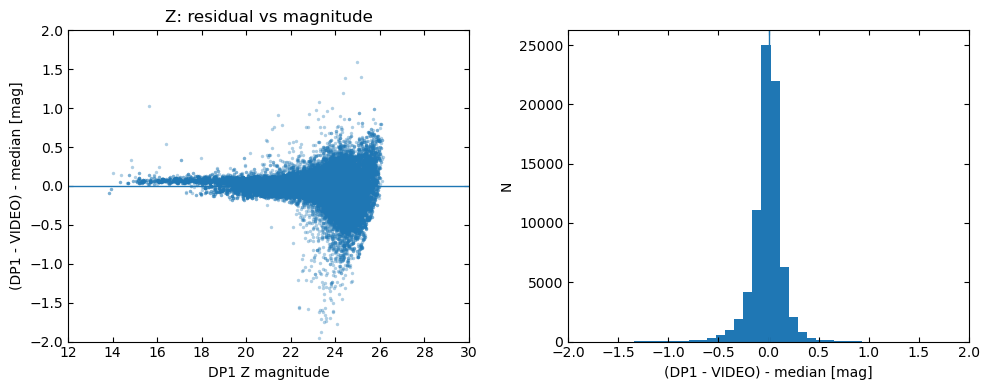

Z band
  VIDEO column: Z_MAG_APER_2
  VIDEO magErr threshold: 0.217
  N: 76412
  median(DP1 - VIDEO): 0.058521983105931596
  NMAD(res): 0.09973241950527063
  bright N (DP1 mag < 18): 612
  bright NMAD(res): 0.021201118637542597
  bright frac |res| > 0.3: 0.0196078431372549


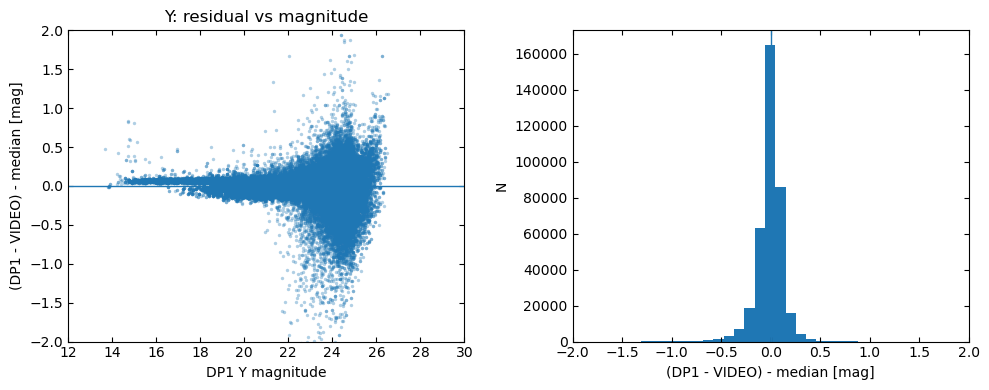

Y band
  VIDEO column: Y_MAG_APER_2
  VIDEO magErr threshold: 0.217
  N: 368376
  median(DP1 - VIDEO): 0.07171575211856762
  NMAD(res): 0.08555382496713726
  bright N (DP1 mag < 18): 2675
  bright NMAD(res): 0.01714470921481826
  bright frac |res| > 0.3: 0.0097196261682243


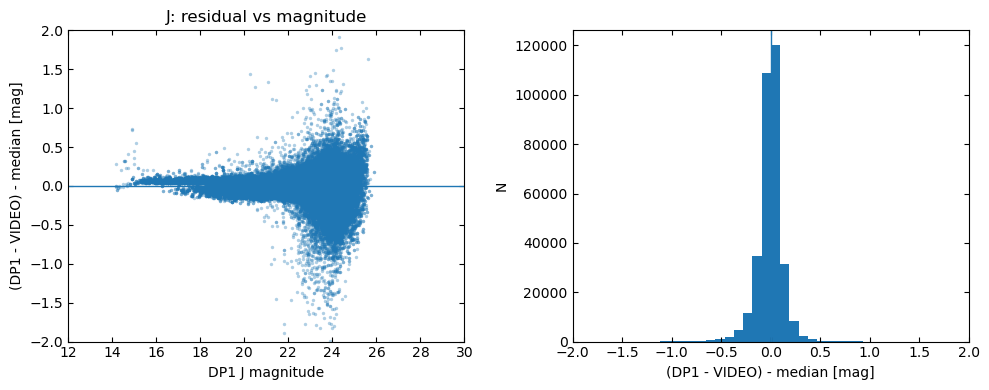

J band
  VIDEO column: J_MAG_APER_2
  VIDEO magErr threshold: 0.217
  N: 327574
  median(DP1 - VIDEO): 0.06017868545461802
  NMAD(res): 0.08531725026374479
  bright N (DP1 mag < 18): 3017
  bright NMAD(res): 0.01666669563507381
  bright frac |res| > 0.3: 0.003646005966191581


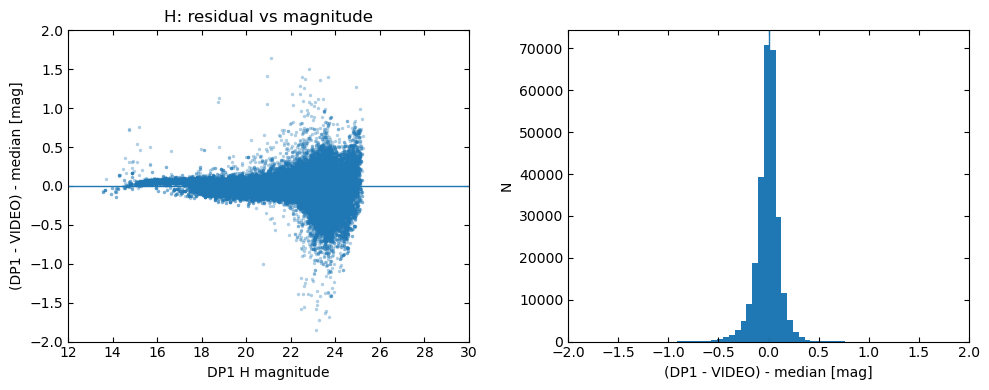

H band
  VIDEO column: H_MAG_APER_2
  VIDEO magErr threshold: 0.217
  N: 270395
  median(DP1 - VIDEO): 0.06322051701382847
  NMAD(res): 0.0824767987108485
  bright N (DP1 mag < 18): 3279
  bright NMAD(res): 0.02214180017582829
  bright frac |res| > 0.3: 0.003964623360780726


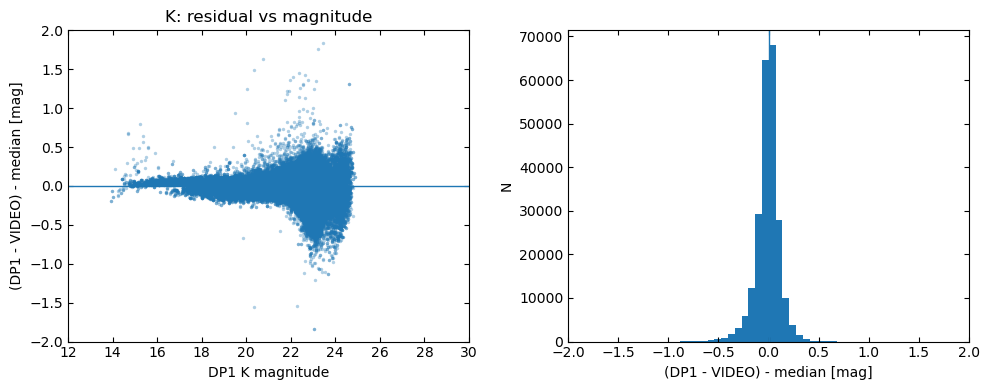

K band
  VIDEO column: KS_MAG_APER_2
  VIDEO magErr threshold: 0.217
  N: 231185
  median(DP1 - VIDEO): 0.06730457003492774
  NMAD(res): 0.0835437976067698
  bright N (DP1 mag < 18): 3407
  bright NMAD(res): 0.02544394281592684
  bright frac |res| > 0.3: 0.0058702670971529205


In [5]:
def video_cols(prefix, aper=VIDEO_APER):
    return {
        "mag":  f"{prefix}_MAG_APER_{aper}",
        "err":  f"{prefix}_MAGERR_APER_{aper}",
        "flag": f"{prefix}_FLAGS",
    }


def video_good_mask(tab, prefix, aper=VIDEO_APER, err_lim=MAGERR_5SIG, require_flag=True):
    cols = video_cols(prefix, aper=aper)

    if not has_col(tab, cols["mag"]):
        raise KeyError(f"Missing VIDEO magnitude column: {cols['mag']}")

    mag = arr(tab, cols["mag"], float)

    if has_col(tab, cols["err"]):
        err = arr(tab, cols["err"], float)
        m = np.isfinite(mag) & np.isfinite(err) & (err > 0) & (err < err_lim)
    else:
        m = np.isfinite(mag)

    if require_flag and has_col(tab, cols["flag"]):
        flag = arr(tab, cols["flag"], int)
        m &= (flag == 0)

    return m


def compare_residual_band(
    band,
    aper=VIDEO_APER,
    err_lim=MAGERR_5SIG,
    xlim=(12, 30),
    ylim=(-2, 2),
):
    if band not in VIDEO_PREFIX:
        raise ValueError(f"No VIDEO mapping for band {band}")

    vprefix = VIDEO_PREFIX[band]
    vcols = video_cols(vprefix, aper=aper)

    if not has_col(vid_box, vcols["mag"]):
        print(f"Skipping {band}: missing VIDEO column {vcols['mag']}")
        return None

    dp1_m = dp1_mag(dp1c, band)
    dp1_good = dp1_band_usable(dp1c, band, snr_min=5.0)

    vid_m_all = arr(vid_box, vcols["mag"], float)
    vid_good_all = video_good_mask(vid_box, vprefix, aper=aper, err_lim=err_lim, require_flag=True)

    good = (
        matched
        & dp1_good
        & vid_good_all[idx]
        & np.isfinite(dp1_m)
        & np.isfinite(vid_m_all[idx])
    )

    if good.sum() == 0:
        print(f"{band}: no good matched sources")
        return None

    dm = dp1_m[good] - vid_m_all[idx[good]]
    const = np.nanmedian(dm)
    res = dm - const
    mag_plot = dp1_m[good]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].scatter(mag_plot, res, s=6, alpha=0.35, linewidths=0)
    axes[0].axhline(0, lw=1)
    axes[0].set_xlim(*xlim)
    axes[0].set_ylim(*ylim)
    axes[0].set_xlabel(f"DP1 {band} magnitude")
    axes[0].set_ylabel("(DP1 - VIDEO) - median [mag]")
    axes[0].set_title(f"{band}: residual vs magnitude")
    axes[0].tick_params(direction="in", top=True, right=True)

    axes[1].hist(res[np.isfinite(res)], bins=60)
    axes[1].axvline(0, lw=1)
    axes[1].set_xlim(*ylim)
    axes[1].set_xlabel("(DP1 - VIDEO) - median [mag]")
    axes[1].set_ylabel("N")
    axes[1].tick_params(direction="in", top=True, right=True)

    plt.tight_layout()
    savefig(f"dp1_video_{band}_residuals.png")
    plt.show()

    print(f"{band} band")
    print("  VIDEO column:", vcols["mag"])
    print(f"  VIDEO magErr threshold: {err_lim:.3f}")
    print("  N:", int(good.sum()))
    print("  median(DP1 - VIDEO):", float(const))
    print("  NMAD(res):", float(nmad(res)))

    bright = mag_plot < 18
    if bright.sum() > 0:
        print("  bright N (DP1 mag < 18):", int(bright.sum()))
        print("  bright NMAD(res):", float(nmad(res[bright])))
        print("  bright frac |res| > 0.3:", float(np.mean(np.abs(res[bright]) > 0.3)))

    return {
        "band": band,
        "mask": good,
        "mag": mag_plot,
        "res": res,
        "median": const,
        "nmad": nmad(res),
    }


residual_results = {}
for band in ["Z", "Y", "J", "H", "K"]:
    try:
        result = compare_residual_band(band, err_lim=MAGERR_5SIG)
        if result is not None:
            residual_results[band] = result
    except Exception as e:
        print(f"Skipping {band} because of error:")
        print(type(e).__name__, e)

### 5.1 Residual summary across the five near-infrared bands

The table below is generated from the same samples and quality cuts as the plots. The measured median offsets and NMAD provide the reference photometric results for scientific reporting.

In [6]:
print("Band   N       median(DP1-VIDEO)    NMAD")
for band, result in residual_results.items():
    print(
        f"{band:4s} "
        f"{len(result['res']):7d} "
        f"{result['median']:18.5f} "
        f"{result['nmad']:10.5f}"
    )

Band   N       median(DP1-VIDEO)    NMAD
Z      76412            0.05852    0.09973
Y     368376            0.07172    0.08555
J     327574            0.06018    0.08532
H     270395            0.06322    0.08248
K     231185            0.06730    0.08354


### 5.2 Bright-residual outliers

Bright sources (`DP1 mag < 18`) are examined for residuals with magnitude above 0.3 mag after subtracting the band median. Such outliers are uncommon (approximately **0.4–1%** in Y, J, H and K, and about **2%** in Z). Multiple DP1 sources associated with the same VIDEO entry and relatively large positional separations can contribute, but neither fully explains all cases.

This compact summary intentionally reports aggregate outlier properties rather than printing individual catalogue row IDs.

In [7]:
def bright_outlier_summary(band, result, bright_limit=18.0, outlier_limit=0.3):
    good = result["mask"]
    mag, residual = result["mag"], result["res"]
    bright = np.isfinite(mag) & np.isfinite(residual) & (mag < bright_limit)
    outlier = bright & (np.abs(residual) > outlier_limit)
    selected_video = idx[good][outlier]
    dup_fraction = np.nan
    if len(selected_video):
        ids, counts = np.unique(selected_video, return_counts=True)
        repeated = ids[counts > 1]
        dup_fraction = np.mean(np.isin(selected_video, repeated))
    n_bright = int(bright.sum())
    n_out = int(outlier.sum())
    return (band, n_bright, n_out,
            n_out / n_bright if n_bright else np.nan, dup_fraction)

print("Band  N bright  N outliers  outlier frac  repeated-VIDEO frac")
for band, result in residual_results.items():
    b, n_bright, n_out, fraction, repeated = bright_outlier_summary(band, result)
    print(f"{b:4s} {n_bright:9d} {n_out:11d} {fraction:12.4%} {repeated:20.4%}")

Band  N bright  N outliers  outlier frac  repeated-VIDEO frac
Z          612          12      1.9608%             50.0000%
Y         2675          26      0.9720%             53.8462%
J         3017          11      0.3646%             54.5455%
H         3279          13      0.3965%             30.7692%
K         3407          20      0.5870%             60.0000%


### 5.3 Magnitude-dependent residual behaviour

Median residuals and positive-residual fractions are evaluated in 0.5-mag bins using the baseline quality-selected sample. The brighter bins show positive residuals in several bands, while the residual median approaches zero over much of the faint population. Bins with very small samples are not used to infer systematic trends.

A combined figure gives a concise view of all five bands without repeating separate exploratory figures.

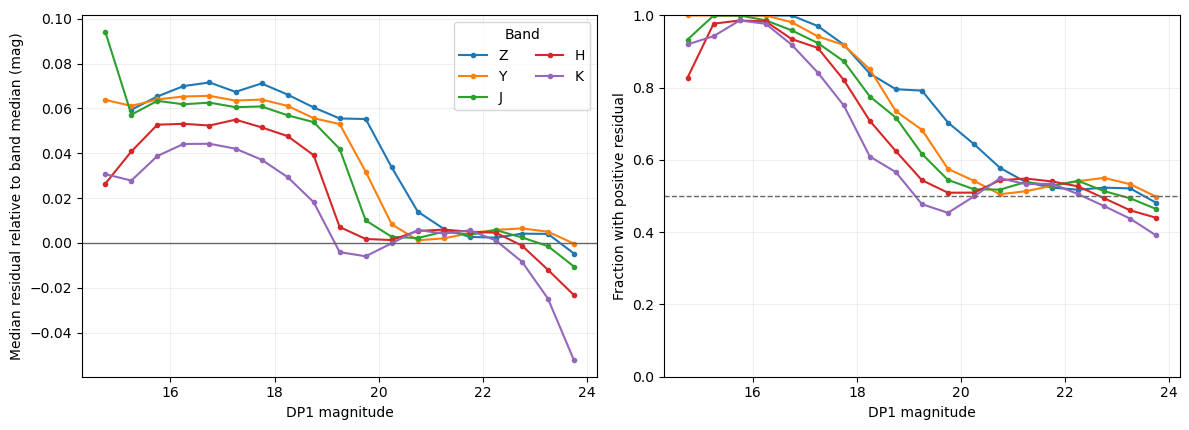

In [8]:
MAG_BINS = np.arange(13, 24.5, 0.5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True)
trend_results = {}
for band, result in residual_results.items():
    magnitude, residual = result["mag"], result["res"]
    centers, medians, fractions, counts = [], [], [], []
    for lower, upper in zip(MAG_BINS[:-1], MAG_BINS[1:]):
        use = (np.isfinite(magnitude) & np.isfinite(residual)
               & (magnitude >= lower) & (magnitude < upper))
        if np.count_nonzero(use) < 30:
            continue
        centers.append((lower + upper) / 2)
        medians.append(np.median(residual[use]))
        fractions.append(np.mean(residual[use] > 0))
        counts.append(np.count_nonzero(use))
    trend_results[band] = dict(mag=np.array(centers), median=np.array(medians),
                               frac_positive=np.array(fractions), n=np.array(counts))
    axes[0].plot(centers, medians, "o-", ms=3, label=band)
    axes[1].plot(centers, fractions, "o-", ms=3, label=band)
axes[0].axhline(0, color="0.4", lw=1)
axes[1].axhline(0.5, color="0.4", lw=1, ls="--")
axes[0].set_ylabel("Median residual relative to band median (mag)")
axes[1].set_ylabel("Fraction with positive residual")
for ax in axes:
    ax.set_xlabel("DP1 magnitude")
    ax.invert_xaxis()
    ax.grid(alpha=0.2)
axes[1].set_ylim(0, 1)
axes[0].legend(title="Band", ncol=2)
fig.tight_layout()
savefig("dp1_video_residual_trends_allbands.png")
plt.show()

### 6. Sensitivity to stricter positional associations

A separate robustness test restricts the baseline comparison to separations below **0.35 arcsec** and retains the closest DP1 source for each VIDEO object. The resulting sample is not used to replace the main photometric comparison: differences in source resolution and deblending mean that the stricter one-to-one selection rejects many otherwise useful matched measurements.

In [9]:
def keep_closest_dp1_per_video_match(current_good_mask):
    """Select one (closest) DP1 row per VIDEO match within a given mask."""
    rows = np.flatnonzero(current_good_mask)
    out = np.zeros(len(current_good_mask), dtype=bool)
    if len(rows) == 0:
        return out
    v_ids = idx[rows]
    separations = sep.arcsec[rows]
    # Sort by VIDEO ID and then separation; the first per VIDEO ID is closest.
    ordering = np.lexsort((separations, v_ids))
    ordered_ids = v_ids[ordering]
    first = np.r_[True, ordered_ids[1:] != ordered_ids[:-1]]
    out[rows[ordering[first]]] = True
    return out

print("Band    N strict    median(DP1-VIDEO)    NMAD")
strict_results = {}
for band, result in residual_results.items():
    selected = result["mask"] & (sep.arcsec < 0.35)
    selected &= keep_closest_dp1_per_video_match(selected)
    dp1_m = dp1_mag(dp1c, band)[selected]
    v_m = arr(vid_box, video_cols(VIDEO_PREFIX[band])["mag"])[idx[selected]]
    difference = dp1_m - v_m
    strict_results[band] = dict(n=int(selected.sum()), median=np.median(difference),
                                nmad=nmad(difference))
    v = strict_results[band]
    print(f"{band:4s} {v['n']:9d} {v['median']:+20.5f} {v['nmad']:10.5f}")

Band    N strict    median(DP1-VIDEO)    NMAD
Z        38925             +0.05718    0.10177
Y       156390             +0.07127    0.08710
J       136784             +0.05904    0.08707
H       113253             +0.06212    0.08469
K        96662             +0.06571    0.08550


### 7. Stellar K-band photometric consistency

VIDEO stars are selected with `KS_CLASS_STAR > 0.7`, `KS_FLAGS = 0` and valid 2-arcsec-aperture photometry. Mutual nearest-neighbour matches within **0.50 arcsec** are used, together with the DP1 K-band forced-aperture, pixel-quality, primary-source and deblending selections.

For the corrected catalogue, **7,036 stars** satisfy the final DP1 cuts. In the well-populated interval **16 ≤ Ks < 22**, **4,799 stars** give a raw DP1–VIDEO median of **+0.109 mag** and NMAD of **0.037 mag** (full stellar sample: +0.106 mag and 0.049 mag). No empirical offset is subtracted from the plotted stellar residuals.

VIDEO-star selection
  CLASS_STAR cut: 0.7
  N VIDEO stars : 25928

Mutual nearest-neighbour matches
  match radius: 0.5 arcsec
  N matched   : 20656
  median sep  : 0.1736237061932036 arcsec
  p90 sep     : 0.3139575279182216 arcsec

VIDEO-star residuals
  reference range       : 16.0 <= Ks < 22.0
  N stars in range      : 4799
  median in range       : 0.10873658835193467 mag
  NMAD in range         : 0.037392284580757384 mag
  full-sample N         : 7036
  full-sample median    : 0.10632121768041891 mag
  full-sample NMAD      : 0.049093481838727304 mag
16 <= Ks < 20: N= 1237, median=+0.1137, NMAD=0.0248
16 <= Ks < 21: N= 2630, median=+0.1102, NMAD=0.0299
16 <= Ks < 22: N= 4799, median=+0.1087, NMAD=0.0374
17 <= Ks < 22: N= 4694, median=+0.1084, NMAD=0.0376
18 <= Ks < 22: N= 4470, median=+0.1079, NMAD=0.0391


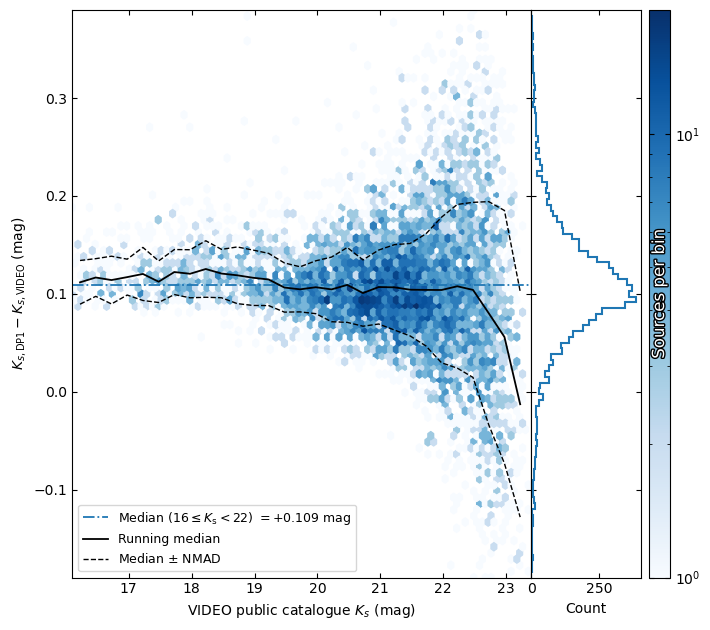

In [10]:
# ============================================================
# Final VIDEO-star K_s residual diagnostic
# ============================================================
#
# The residuals shown here are the measured DP1/VIDEO
# differences after placing both catalogues on the same
# AB magnitude convention. No additional empirical shift
# is subtracted.
#
# A well-populated stellar interval, 16 <= Ks < 22, is used
# only to quantify the characteristic median difference.
# ============================================================


MAGERR_5SIG = 2.5 / np.log(10) / 5.0
MATCH_RADIUS = 0.5 * u.arcsec
STAR_CLASS_CUT = 0.7
REFERENCE_RANGE = (16.0, 22.0)

# ------------------------------------------------------------
# VIDEO stellar selection
# ------------------------------------------------------------

ks_cls = np.asarray(
    vid_box["KS_CLASS_STAR"],
    float,
)

ks_flag = np.asarray(
    vid_box["KS_FLAGS"],
    int,
)

ks_mag = np.asarray(
    vid_box["KS_MAG_APER_2"],
    float,
)

ks_err = np.asarray(
    vid_box["KS_MAGERR_APER_2"],
    float,
)

vid_star = (
    np.isfinite(ks_cls)
    & np.isfinite(ks_mag)
    & np.isfinite(ks_err)
    & (ks_flag == 0)
    & (ks_err > 0)
    & (ks_err < MAGERR_5SIG)
    & (ks_cls > STAR_CLASS_CUT)
)

vid_star_cat = vid_box[vid_star]
c_vid_star = c_vid_box[vid_star]

print("VIDEO-star selection")
print(
    "  CLASS_STAR cut:",
    STAR_CLASS_CUT,
)
print(
    "  N VIDEO stars :",
    len(vid_star_cat),
)

# ------------------------------------------------------------
# Mutual nearest-neighbour matching
# ------------------------------------------------------------

idx_d2v, sep_d2v, _ = match_coordinates_sky(
    c_dp1,
    c_vid_star,
)

idx_v2d, sep_v2d, _ = match_coordinates_sky(
    c_vid_star,
    c_dp1,
)

video_idx = np.arange(
    len(c_vid_star)
)

dp1_idx = idx_v2d

mutual = (
    (sep_v2d < MATCH_RADIUS)
    & (idx_d2v[dp1_idx] == video_idx)
    & (sep_d2v[dp1_idx] < MATCH_RADIUS)
)

video_keep = video_idx[mutual]
dp1_keep = dp1_idx[mutual]

dp1m = dp1c[dp1_keep]
vidm = vid_star_cat[video_keep]

print("\nMutual nearest-neighbour matches")
print(
    "  match radius:",
    MATCH_RADIUS.to_value(u.arcsec),
    "arcsec",
)
print(
    "  N matched   :",
    len(dp1m),
)
print(
    "  median sep  :",
    np.median(
        sep_v2d[mutual].to_value(u.arcsec)
    ),
    "arcsec",
)
print(
    "  p90 sep     :",
    np.percentile(
        sep_v2d[mutual].to_value(u.arcsec),
        90,
    ),
    "arcsec",
)

# ------------------------------------------------------------
# DP1 and VIDEO photometry
# ------------------------------------------------------------

dp1_k_mag = dp1_mag(dp1m, "K")

dp1_k_good = dp1_band_usable(
    dp1m,
    "K",
    snr_min=5.0,
)

dp1_nchild = np.asarray(
    dp1m[
        "VIRCAM_K_m_deblend_nChild"
    ],
    int,
)

dp1_primary = np.asarray(
    dp1m[
        "VIRCAM_K_m_detect_isPrimary"
    ],
    int,
)

vid_k_mag = np.asarray(
    vidm["KS_MAG_APER_2"],
    float,
)

vid_k_err = np.asarray(
    vidm["KS_MAGERR_APER_2"],
    float,
)


# ------------------------------------------------------------
# Final photometric-quality cuts
# ------------------------------------------------------------

good = (
    dp1_k_good
    & np.isfinite(dp1_k_mag)
    & np.isfinite(vid_k_mag)
    & np.isfinite(vid_k_err)
    & (vid_k_err > 0)
    & (vid_k_err < MAGERR_5SIG)
    & (dp1_primary == 1)
    & (dp1_nchild == 0)
)

x = vid_k_mag[good]

y_raw = (
    dp1_k_mag[good]
    - vid_k_mag[good]
)

# No empirical stellar residual is subtracted
y = y_raw.copy()


# ------------------------------------------------------------
# Reference stellar interval
# ------------------------------------------------------------

reference_mask = (
    np.isfinite(x)
    & np.isfinite(y)
    & (x >= REFERENCE_RANGE[0])
    & (x < REFERENCE_RANGE[1])
)

if reference_mask.sum() < 20:
    raise RuntimeError(
        f"Too few stars in reference range {REFERENCE_RANGE}: "
        f"N={reference_mask.sum()}"
    )

reference_median = np.nanmedian(y_raw[reference_mask])
reference_nmad = nmad(y_raw[reference_mask])

# Keep the measured residuals unchanged
y = y_raw.copy()

print("\nVIDEO-star residuals")
print(
    f"  reference range       : "
    f"{REFERENCE_RANGE[0]} <= Ks < {REFERENCE_RANGE[1]}"
)
print(
    "  N stars in range      :",
    int(reference_mask.sum()),
)
print(
    "  median in range       :",
    float(reference_median),
    "mag",
)
print(
    "  NMAD in range         :",
    float(reference_nmad),
    "mag",
)
print(
    "  full-sample N         :",
    int(np.isfinite(y).sum()),
)
print(
    "  full-sample median    :",
    float(np.nanmedian(y)),
    "mag",
)
print(
    "  full-sample NMAD      :",
    float(nmad(y)),
    "mag",
)


for lo, hi in [
    (16, 20),
    (16, 21),
    (16, 22),
    (17, 22),
    (18, 22),
]:
    m = (
        np.isfinite(x)
        & np.isfinite(y_raw)
        & (x >= lo)
        & (x < hi)
    )

    print(
        f"{lo:2.0f} <= Ks < {hi:2.0f}: "
        f"N={m.sum():5d}, "
        f"median={np.nanmedian(y_raw[m]):+.4f}, "
        f"NMAD={nmad(y_raw[m]):.4f}"
    )

# ------------------------------------------------------------
# Running statistics for this figure
# ------------------------------------------------------------

def stellar_running_stats(x, y, bin_edges, min_per_bin=10):
    xc = []
    med = []
    scat = []

    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        sel = (
            np.isfinite(x)
            & np.isfinite(y)
            & (x >= lo)
            & (x < hi)
        )

        if np.sum(sel) < min_per_bin:
            continue

        yy = y[sel]

        xc.append(0.5 * (lo + hi))
        med.append(np.nanmedian(yy))
        scat.append(nmad(yy))

    return (
        np.asarray(xc),
        np.asarray(med),
        np.asarray(scat),
    )


xlim = (16.1, 23.4)
ylim = (-0.19, 0.39)

bin_edges = np.arange(
    xlim[0],
    xlim[1] + 0.0001,
    0.25,
)

xc, ymed, ysig = stellar_running_stats(
    x,
    y,
    bin_edges,
    min_per_bin=10,
)

# ------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------

fig = plt.figure(figsize=(7.2, 6.4))
ax = fig.add_subplot(111)

divider = make_axes_locatable(ax)

ax_r = divider.append_axes(
    "right",
    size=1.1,
    pad=0.0,
    sharey=ax,
)

cax = divider.append_axes(
    "right",
    size="4.5%",
    pad=0.08,
)

# ------------------------------------------------------------
# Main density plot
# ------------------------------------------------------------

hb = ax.hexbin(
    x,
    y,
    gridsize=80,
    extent=(
        xlim[0],
        xlim[1],
        ylim[0],
        ylim[1],
    ),
    mincnt=1,
    bins="log",
    cmap="Blues",
)

# Median measured from the reference stellar interval
ax.axhline(
    reference_median,
    lw=1.3,
    ls="-.",
    label=(
        rf"Median ($16\leq K_{{\rm s}}<22$) "
        rf"$= {reference_median:+.3f}$ mag"
    ),
)

# Running median and scatter
ax.plot(
    xc,
    ymed,
    lw=1.3,
    color="black",
    label="Running median",
)

ax.plot(
    xc,
    ymed + ysig,
    lw=1.0,
    ls="--",
    color="black",
    label=r"Median $\pm$ NMAD",
)

ax.plot(
    xc,
    ymed - ysig,
    lw=1.0,
    ls="--",
    color="black",
)

# ------------------------------------------------------------
# Main-axis formatting
# ------------------------------------------------------------

ax.set_xlim(*xlim)
ax.set_ylim(*ylim)

ax.set_xlabel(
    r"VIDEO public catalogue $K_s$ (mag)",
    fontsize=10,
)

ax.set_ylabel(
    r"$K_{s,\mathrm{DP1}} - K_{s,\mathrm{VIDEO}}$ (mag)",
    fontsize=10
)

ax.tick_params(
    direction="in",
    top=True,
    right=True,
)

ax.legend(
    loc="lower left",
    frameon=True,
    fontsize=9,
)

# ------------------------------------------------------------
# Marginal residual histogram
# ------------------------------------------------------------

bins_y = np.linspace(
    ylim[0],
    ylim[1],
    100,
)

ax_r.hist(
    y,
    bins=bins_y,
    histtype="step",
    lw=1.5,
    orientation="horizontal",
)

ax_r.tick_params(
    direction="in",
    top=True,
    right=True,
    labelleft=False,
)

ax_r.set_xlabel("Count")

# Full-sample statistics
txt = (
    rf"$N = {np.isfinite(y).sum()}$"
    "\n"
    rf"median $= {np.nanmedian(y):+.3f}$"
    "\n"
    rf"$\sigma_{{\rm NMAD}} = {nmad(y):.3f}$"
)



# ------------------------------------------------------------
# Colour bar
# ------------------------------------------------------------

cb = fig.colorbar(
    hb,
    cax=cax,
)

cb.ax.tick_params(
    which="both",
    direction="in",
    right=True,
    left=True,
)

cb.set_label("")

cb.ax.text(
    0.5,
    0.5,
    "Sources per bin",
    transform=cb.ax.transAxes,
    rotation=90,
    ha="center",
    va="center",
    color="white",
    fontsize=12,
    path_effects=[
        pe.withStroke(
            linewidth=2,
            foreground="black",
        )
    ],
)

plt.tight_layout()
fig.savefig(
    OUTDIR / "dp1_video_stars_residuals.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

### 7.1 Dependence on the VIDEO aperture definition

The measured stellar residual depends strongly on the chosen VIDEO aperture. In **16 ≤ Ks < 22**, the typical residual is approximately **−0.072 mag** for the 1.41-arcsec aperture, **+0.109 mag** for the 2-arcsec aperture, and **+0.206 mag** for the 2.83-arcsec aperture. The difference is therefore not a pure photometric zero-point offset. No correction is derived or applied from this comparison.

DP1 stellar quality base sample
  N matched stellar rows : 20656
  N after DP1 K cuts     : 7036


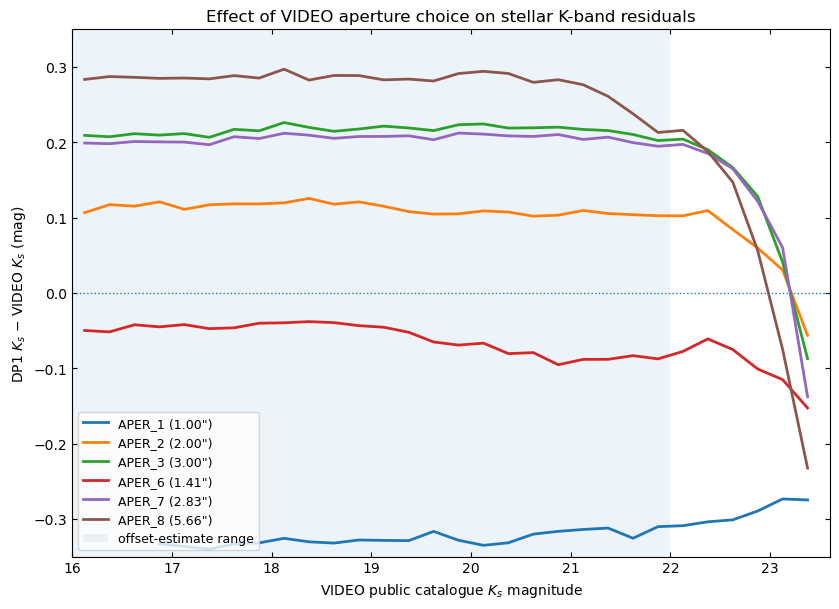


VIDEO aperture-choice summary
Shift-summary range: 16.0 <= Ks < 22.0

aper  diam   N_all   med_all  nmad_all   N_shift  med_shift  nmad_shift
   1  1.00    1616   -0.3120    0.0372       809    -0.3242      0.0246
   2  2.00    6904   +0.1059    0.0488      4782    +0.1086      0.0371
   3  3.00    6611   +0.2124    0.0483      4910    +0.2172      0.0393
   6  1.41    6922   -0.0745    0.0714      4407    -0.0717      0.0593
   7  2.83    6678   +0.2018    0.0470      4915    +0.2059      0.0381
   8  5.66    4911   +0.2700    0.0610      3843    +0.2794      0.0464


In [11]:
# ============================================================
# VIDEO aperture-choice diagnostic for the matched stellar sample
# ============================================================
#   dp1m : matched DP1 sources
#   vidm : matched VIDEO stars
#
# The purpose is to see how the raw DP1 - VIDEO residual changes
# when different VIDEO aperture magnitudes are used.

import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def running_stats(x, y, bin_edges, min_per_bin=10):
    xc, med, scat, nbin = [], [], [], []

    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        m = (
            np.isfinite(x)
            & np.isfinite(y)
            & (x >= lo)
            & (x < hi)
        )

        if m.sum() < min_per_bin:
            continue

        yy = y[m]

        xc.append(0.5 * (lo + hi))
        med.append(np.nanmedian(yy))
        scat.append(nmad(yy))
        nbin.append(m.sum())

    return (
        np.asarray(xc),
        np.asarray(med),
        np.asarray(scat),
        np.asarray(nbin),
    )


def optional_bool_column(tab, col, default=True):
    if col in tab.colnames:
        return np.asarray(tab[col], bool)
    return np.full(len(tab), default, dtype=bool)


def optional_int_column(tab, col, default=0):
    if col in tab.colnames:
        return np.asarray(tab[col], int)
    return np.full(len(tab), default, dtype=int)


# ------------------------------------------------------------
# Check that this cell is run after the stellar-match cell
# ------------------------------------------------------------

for required_name in ["dp1m", "vidm"]:
    if required_name not in globals():
        raise RuntimeError(
            f"`{required_name}` is not defined. "
            "Run the VIDEO-star stellar-offset cell first."
        )


# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

MAGERR_5SIG = 2.5 / np.log(10) / 5.0

# Safe stellar range used for offset summaries
SHIFT_RANGE = (16.0, 22.0)

# Plot range
XLIM = (16.0, 23.6)
YLIM = (-0.35, 0.35)

# VIDEO aperture numbers and approximate aperture diameters in arcsec.
# These labels are used only for the legend.
apertures = {
    1: 1.00,
    2: 2.00,
    3: 3.00,
    6: 1.41,
    7: 2.83,
    8: 5.66,
}


# ------------------------------------------------------------
# DP1 K-band quality selection
# ------------------------------------------------------------

dp1_k_mag = dp1_mag(dp1m, "K")

dp1_primary = optional_bool_column(
    dp1m,
    "VIRCAM_K_m_detect_isPrimary",
    default=True,
)

dp1_nchild = optional_int_column(
    dp1m,
    "VIRCAM_K_m_deblend_nChild",
    default=0,
)

base_dp1 = (
    dp1_band_usable(
        dp1m,
        "K",
        snr_min=5.0,
    )
    & dp1_primary
    & (dp1_nchild == 0)
)

print("DP1 stellar quality base sample")
print("  N matched stellar rows :", len(dp1m))
print("  N after DP1 K cuts     :", int(base_dp1.sum()))

# ------------------------------------------------------------
# Compare different VIDEO apertures
# ------------------------------------------------------------

summary_rows = []

fig, ax = plt.subplots(figsize=(8.5, 6.2))

bin_edges = np.arange(XLIM[0], XLIM[1] + 0.001, 0.25)

for aper, diam in apertures.items():

    mag_col = f"KS_MAG_APER_{aper}"
    err_col = f"KS_MAGERR_APER_{aper}"

    if mag_col not in vidm.colnames or err_col not in vidm.colnames:
        print(f"Skipping APER_{aper}: missing {mag_col} or {err_col}")
        continue

    vid_mag = np.asarray(vidm[mag_col], float)
    vid_err = np.asarray(vidm[err_col], float)

    good = (
        base_dp1
        & np.isfinite(vid_mag)
        & np.isfinite(vid_err)
        & (vid_err > 0)
        & (vid_err < MAGERR_5SIG)
    )

    x = vid_mag[good]
    y = dp1_k_mag[good] - vid_mag[good]

    # Restrict only the plotted/statistical range.
    use = (
        np.isfinite(x)
        & np.isfinite(y)
        & (x >= XLIM[0])
        & (x <= XLIM[1])
        & (y >= YLIM[0])
        & (y <= YLIM[1])
    )

    x = x[use]
    y = y[use]

    if len(y) < 30:
        print(f"Skipping APER_{aper}: too few usable stars")
        continue

    xc, ymed, ysig, nbin = running_stats(
        x,
        y,
        bin_edges,
        min_per_bin=10,
    )

    ax.plot(
        xc,
        ymed,
        lw=2,
        label=f"APER_{aper} ({diam:.2f}\")",
    )

    shift_mask = (
        np.isfinite(x)
        & np.isfinite(y)
        & (x >= SHIFT_RANGE[0])
        & (x < SHIFT_RANGE[1])
    )

    summary_rows.append(
        {
            "aper": aper,
            "diam": diam,
            "N_all": len(y),
            "med_all": np.nanmedian(y),
            "nmad_all": nmad(y),
            "N_shift": int(shift_mask.sum()),
            "med_shift": np.nanmedian(y[shift_mask]) if shift_mask.sum() else np.nan,
            "nmad_shift": nmad(y[shift_mask]) if shift_mask.sum() else np.nan,
        }
    )


# ------------------------------------------------------------
# Plot formatting
# ------------------------------------------------------------

ax.axhline(0, lw=1.0, ls=":")
ax.axvspan(
    SHIFT_RANGE[0],
    SHIFT_RANGE[1],
    alpha=0.08,
    label="offset-estimate range",
)

ax.set_xlim(*XLIM)
ax.set_ylim(*YLIM)

ax.set_xlabel("VIDEO public catalogue $K_s$ magnitude")
ax.set_ylabel("DP1 $K_s$ − VIDEO $K_s$ (mag)")
ax.set_title("Effect of VIDEO aperture choice on stellar K-band residuals")
ax.tick_params(direction="in", top=True, right=True)
ax.legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

print()
print("VIDEO aperture-choice summary")
print(f"Shift-summary range: {SHIFT_RANGE[0]} <= Ks < {SHIFT_RANGE[1]}")
print()
print("aper  diam   N_all   med_all  nmad_all   N_shift  med_shift  nmad_shift")

for row in summary_rows:
    print(
        f"{row['aper']:>4d}  "
        f"{row['diam']:>4.2f}  "
        f"{row['N_all']:>6d}  "
        f"{row['med_all']:>+8.4f}  "
        f"{row['nmad_all']:>8.4f}  "
        f"{row['N_shift']:>8d}  "
        f"{row['med_shift']:>+9.4f}  "
        f"{row['nmad_shift']:>10.4f}"
    )

### Interpertation

The measured stellar residual depends strongly on the adopted VIDEO aperture. In the reference interval 16 ≤ Ks < 22, the median DP1–VIDEO residual is approximately −0.072 mag for the 1.41-arcsec aperture, +0.109 mag for the 2.00-arcsec aperture and +0.206 mag for the 2.83-arcsec aperture.

The comparison uses aperture-specific VIDEO uncertainty selections, so the contributing stellar samples are not completely identical. Nevertheless, the strong dependence on aperture size demonstrates that the measured offsets cannot be interpreted as pure photometric zero-point differences.

No empirical correction is derived or applied from this comparison.


### 8. K-band magnitude distributions and matching selection

The quality-selected samples contain **283,984** DP1 K-band sources and **382,234** VIDEO sources within the adopted DP1 spatial comparison region. There are **231,185** accepted associations within 0.50 arcsec, **213,964** within 0.35 arcsec, and **96,662** after retaining the closest DP1 association for each VIDEO object. The latter restriction illustrates the effect of ambiguous associations; it is not the main science-sample definition.

Unmatched catalogue histograms have different selection functions and should not be used alone to infer relative survey depths.

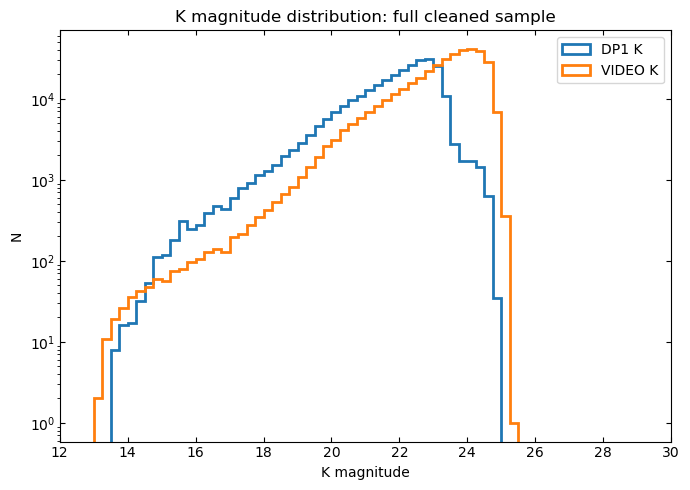

K histogram mode: full cleaned sample
DP1 K N: 283984
VIDEO K N: 382234


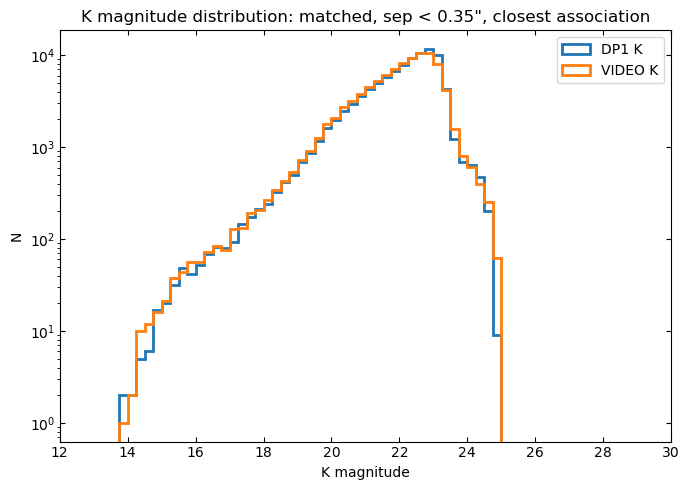

K histogram mode: matched, sep < 0.35", closest association
DP1 K N: 96662
VIDEO K N: 96662


In [12]:
def plot_histogram_comparison(
    band,
    aper=VIDEO_APER,
    err_lim=MAGERR_5SIG,
    matched_only=False,
    match_sep_arcsec=0.35,
    keep_closest_match=True,
):
    if band not in VIDEO_PREFIX:
        raise ValueError(f"No VIDEO mapping for {band}")

    vprefix = VIDEO_PREFIX[band]
    vcols = video_cols(vprefix, aper=aper)

    dp1_m = dp1_mag(dp1c, band)
    dp1_good = dp1_band_usable(
        dp1c,
        band,
        snr_min=5.0,
    )

    vid_m_all = arr(vid_box, vcols["mag"], float)
    vid_good_all = video_good_mask(
        vid_box,
        vprefix,
        aper=aper,
        err_lim=err_lim,
        require_flag=True,
    )

    if matched_only:
        # Same logic as residual-validation sample
        good = (
            matched
            & dp1_good
            & vid_good_all[idx]
            & np.isfinite(dp1_m)
            & np.isfinite(vid_m_all[idx])
        )

        if match_sep_arcsec is not None:
            good &= sep.arcsec < match_sep_arcsec

        if keep_closest_match:
            good &= keep_closest_dp1_per_video_match(good)

        dp1_plot = dp1_m[good]
        vid_plot = vid_m_all[idx[good]]

        label_suffix = (
            f"matched, sep < {match_sep_arcsec:.2f}\""
            if match_sep_arcsec is not None
            else "matched"
        )
        if keep_closest_match:
            label_suffix += ", closest association"

    else:
        # Full cleaned catalogue comparison, not matched one-to-one
        dp1_plot = dp1_m[dp1_good & np.isfinite(dp1_m)]
        vid_plot = vid_m_all[vid_good_all & np.isfinite(vid_m_all)]

        label_suffix = "full cleaned sample"

    bins = np.arange(12, 30.1, 0.25)

    plt.figure(figsize=(7, 5))

    plt.hist(
        dp1_plot,
        bins=bins,
        histtype="step",
        lw=2,
        label=f"DP1 {band}",
    )

    plt.hist(
        vid_plot,
        bins=bins,
        histtype="step",
        lw=2,
        label=f"VIDEO {band}",
    )

    plt.xlabel(f"{band} magnitude")
    plt.ylabel("N")
    plt.title(f"{band} magnitude distribution: {label_suffix}")
    plt.yscale("log")
    plt.legend()

    ax = plt.gca()
    ax.set_xlim(12, 30)
    ax.tick_params(direction="in", top=True, right=True)

    plt.tight_layout()

    if matched_only:
        savefig(f"dp1_video_{band}_histogram_matched.png")
    else:
        savefig(f"dp1_video_{band}_histogram_full_cleaned.png")

    plt.show()

    print(f"{band} histogram mode:", label_suffix)
    print(f"DP1 {band} N:", int(len(dp1_plot)))
    print(f"VIDEO {band} N:", int(len(vid_plot)))

plot_histogram_comparison("K", matched_only=False)
plot_histogram_comparison("K", matched_only=True, match_sep_arcsec=0.35)

In [13]:
def match_count_ladder(band, aper=VIDEO_APER, err_lim=MAGERR_5SIG):
    vprefix = VIDEO_PREFIX[band]
    vcols = video_cols(vprefix, aper=aper)

    dp1_m = dp1_mag(dp1c, band)
    dp1_good = dp1_band_usable(dp1c, band, snr_min=5.0,)

    vid_m_all = arr(vid_box, vcols["mag"], float)
    vid_good_all = video_good_mask(
        vid_box, vprefix, aper=aper, err_lim=err_lim, require_flag=True
    )

    base = (
        matched
        & dp1_good
        & vid_good_all[idx]
        & np.isfinite(dp1_m)
        & np.isfinite(vid_m_all[idx])
    )

    sep05 = base & (sep.arcsec < 0.50)
    sep035 = base & (sep.arcsec < 0.35)

    closest035 = sep035 & keep_closest_dp1_per_video_match(sep035)

    print(f"{band} count ladder")
    print("Full cleaned DP1       :", int((dp1_good & np.isfinite(dp1_m)).sum()))
    print("Full cleaned VIDEO     :", int((vid_good_all & np.isfinite(vid_m_all)).sum()))
    print("Matched, sep < 0.50    :", int(sep05.sum()))
    print("Matched, sep < 0.35    :", int(sep035.sum()))
    print("sep < 0.35 + closest   :", int(closest035.sum()))

match_count_ladder("K")

K count ladder
Full cleaned DP1       : 283984
Full cleaned VIDEO     : 382234
Matched, sep < 0.50    : 231185
Matched, sep < 0.35    : 213964
sep < 0.35 + closest   : 96662


### 9. Optical–near-infrared and single-survey colour–colour distributions

Each plotted colour requires **all of its contributing bands** to pass independent forced-photometry S/N ≥ 5 and pixel-quality selections. The resulting samples are therefore smaller than the single-band catalogues. Distinct features of the diagrams, including a blue locus and a broader red population, remain visible in the clean selections.

The optical-only `g−r` versus `r−i` comparison provides a complementary optical diagnostic, while `Y−J` versus `J−K` probes the near-infrared colour structure.

In [14]:
from matplotlib.colors import LogNorm


def colour_plot_mask(
    x_bands,
    y_bands,
    xlim=None,
    ylim=None,
    snr_min=5.0,
):

    used_bands = sorted(
        set(list(x_bands) + list(y_bands))
    )

    mask = np.ones(
        len(dp1c),
        dtype=bool,
    )

    for band in used_bands:
        mask &= dp1_band_usable(
            dp1c,
            band,
            snr_min=snr_min,
        )

    x = dp1_colour(
        dp1c,
        x_bands[0],
        x_bands[1],
    )

    y = dp1_colour(
        dp1c,
        y_bands[0],
        y_bands[1],
    )

    mask &= (
        np.isfinite(x)
        & np.isfinite(y)
    )

    if xlim is not None:
        mask &= (
            (x > xlim[0])
            & (x < xlim[1])
        )

    if ylim is not None:
        mask &= (
            (y > ylim[0])
            & (y < ylim[1])
        )

    return x, y, mask


def plot_colour_colour(
    x_bands,
    y_bands,
    xlim,
    ylim,
    title,
    bins=180,
    snr_min=5.0,
):

    x, y, mask = colour_plot_mask(
        x_bands,
        y_bands,
        xlim=xlim,
        ylim=ylim,
        snr_min=snr_min,
    )

    print("\n" + title)
    print(
        "  bands used:",
        sorted(
            set(
                list(x_bands)
                + list(y_bands)
            )
        ),
    )
    print(
        "  N selected:",
        int(mask.sum()),
    )

    plt.figure(figsize=(6.5, 6))

    plt.hist2d(
        x[mask],
        y[mask],
        bins=bins,
        range=[xlim, ylim],
        cmap="Greys",
        cmin=1,
        norm=LogNorm(vmin=1),
    )

    plt.xlabel(
        f"{x_bands[0]} - {x_bands[1]}"
    )
    plt.ylabel(
        f"{y_bands[0]} - {y_bands[1]}"
    )
    plt.title(title)

    plt.colorbar(
        label="Number of sources"
    )

    plt.gca().tick_params(
        direction="in",
        top=True,
        right=True,
    )

    plt.tight_layout()

    fname = (
        title.lower()
        .replace(" ", "_")
        .replace(":", "")
        .replace("/", "_")
        + ".png"
    )

    savefig(fname)

    plt.show()

    return mask


Clean colour-colour: g-i versus J-K
  bands used: ['J', 'K', 'g', 'i']
  N selected: 69321


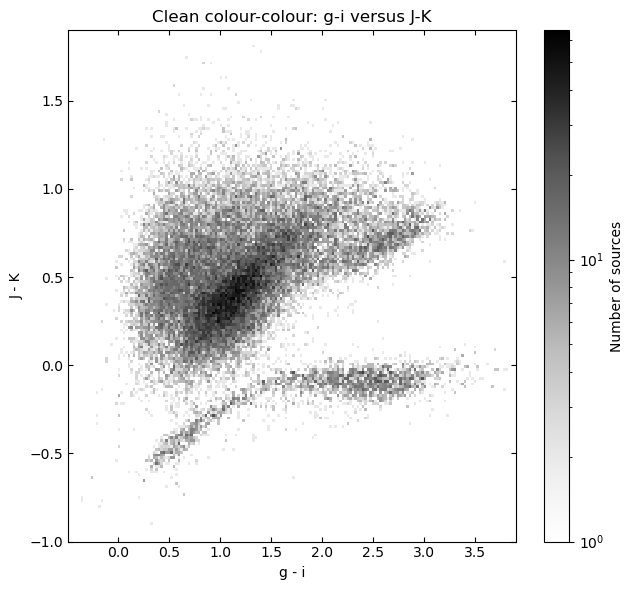


Clean colour-colour: u-i versus J-K
  bands used: ['J', 'K', 'i', 'u']
  N selected: 20000


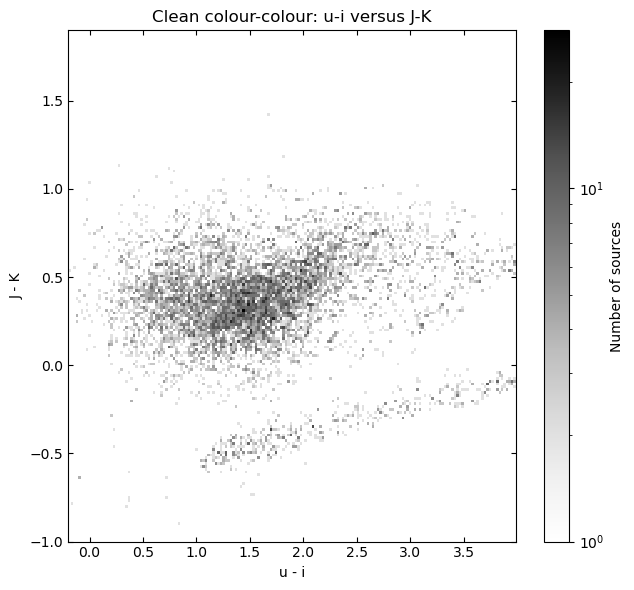


Clean colour-colour: r-i versus J-K
  bands used: ['J', 'K', 'i', 'r']
  N selected: 73070


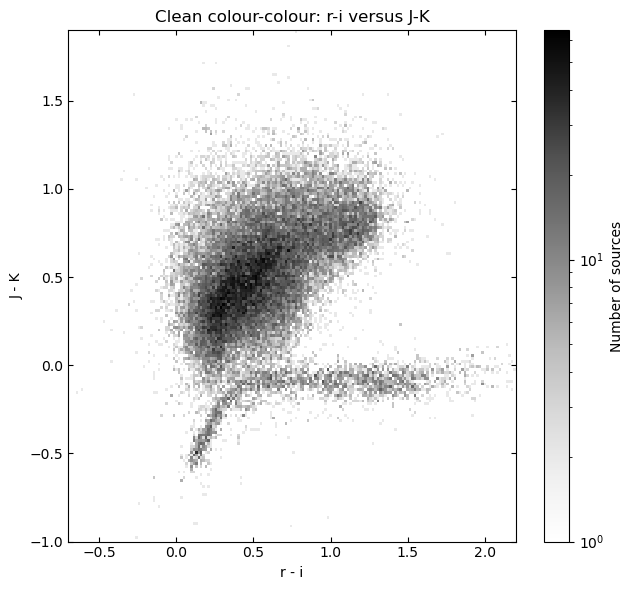


Clean optical colour-colour: g-r versus r-i
  bands used: ['g', 'i', 'r']
  N selected: 142011


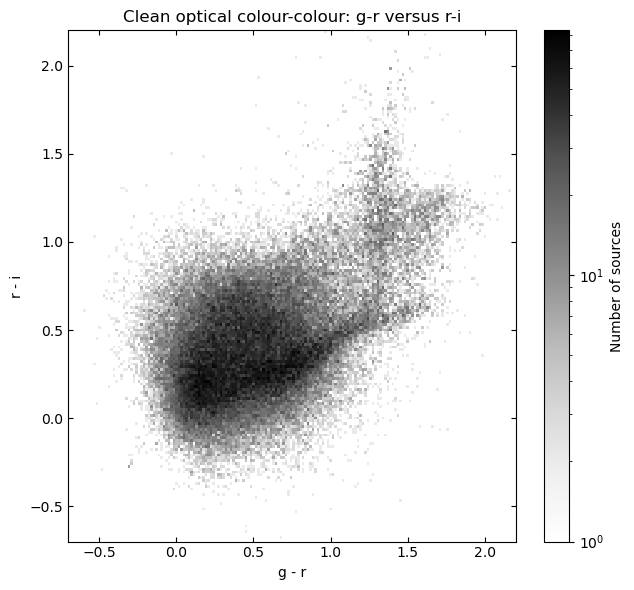


Clean NIR colour-colour: Y-J versus J-K
  bands used: ['J', 'K', 'Y']
  N selected: 238739


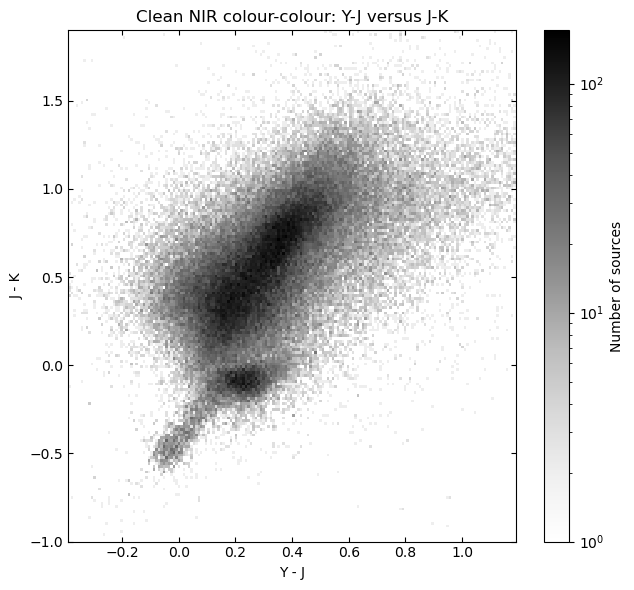

In [15]:
m_gi_JK = plot_colour_colour(
    x_bands=("g", "i"),
    y_bands=("J", "K"),
    xlim=(-0.49, 3.9),
    ylim=(-1.0, 1.9),
    title="Clean colour-colour: g-i versus J-K",
)

try:
    m_ui_JK = plot_colour_colour(
        x_bands=("u", "i"),
        y_bands=("J", "K"),
        xlim=(-0.2, 3.99),
        ylim=(-1.0, 1.9),
        title="Clean colour-colour: u-i versus J-K",
    )
except KeyError as e:
    print("Skipping u-i versus J-K because a required column is missing:")
    print(e)

try:
    m_ri_JK = plot_colour_colour(
        x_bands=("r", "i"),
        y_bands=("J", "K"),
        xlim=(-0.7, 2.2),
        ylim=(-1.0, 1.9),
        title="Clean colour-colour: r-i versus J-K",
    )
except KeyError as e:
    print("Skipping r-i versus J-K because a required column is missing:")
    print(e)

try:
    m_gr_ri = plot_colour_colour(
        x_bands=("g", "r"),
        y_bands=("r", "i"),
        xlim=(-0.7, 2.2),
        ylim=(-0.7, 2.2),
        title="Clean optical colour-colour: g-r versus r-i",
    )
except KeyError as e:
    print("Skipping g-r versus r-i because a required column is missing:")
    print(e)

try:
    m_YJ_JK = plot_colour_colour(
        x_bands=("Y", "J"),
        y_bands=("J", "K"),
        xlim=(-0.39, 1.19),
        ylim=(-1.0, 1.9),
        title="Clean NIR colour-colour: Y-J versus J-K",
    )
except KeyError as e:
    print("Skipping Y-J versus J-K because a required column is missing:")
    print(e)

### 10. Empirical colour locus

An empirical locus is estimated from point-like sources in the clean `g−i` versus `J−K` distribution. The fitted curve and corresponding colour residual are **diagnostics of catalogue coherence**, not a classification rule or a photometric calibration. The selection uses available primary-source and extendedness information; the reported sample contains approximately **29,638 objects**.

N selected: 29638
extendedness column: ComCam_i_m_base_ClassificationExtendedness_value
primary column: VIRCAM_K_m_detect_isPrimary


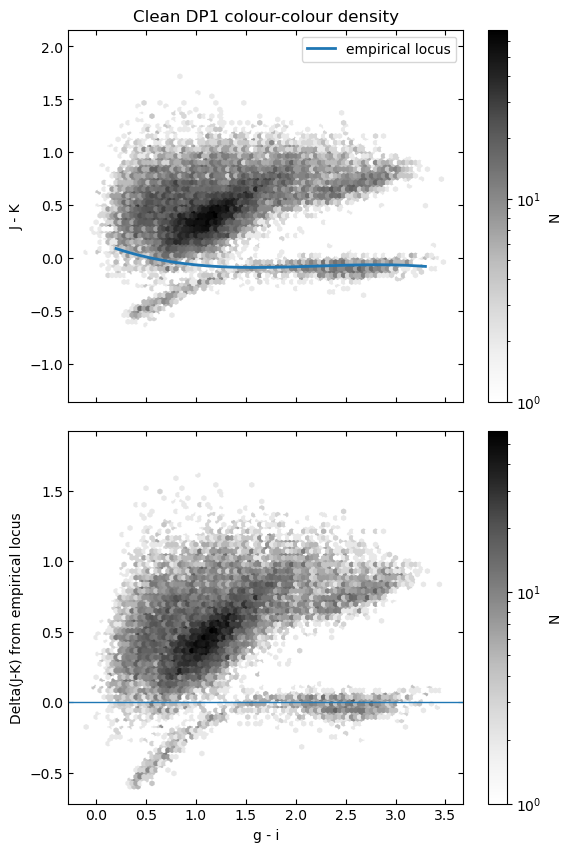

In [16]:
def get_optional_column(tab, candidates, dtype=float):
    for col in candidates:
        if has_col(tab, col):
            return np.asarray(tab[col], dtype=dtype), col
    return None, None


ext, ext_col = get_optional_column(
    dp1c,
    [
        "ComCam_i_m_base_ClassificationExtendedness_value",
        "VIRCAM_K_m_base_ClassificationExtendedness_value",
    ],
    dtype=float,
)

primary, primary_col = get_optional_column(
    dp1c,
    [
        "VIRCAM_K_m_detect_isPrimary",
        "ComCam_i_m_detect_isPrimary",
    ],
    dtype=bool,
)

mask = (
    dp1_band_usable(dp1c, "g", snr_min=5.0)
    & dp1_band_usable(dp1c, "i", snr_min=5.0)
    & dp1_band_usable(dp1c, "J", snr_min=5.0)
    & dp1_band_usable(dp1c, "K", snr_min=5.0)
)

if primary is not None:
    mask &= primary

if ext is not None:
    mask &= np.isfinite(ext)

mask &= dp1_mag(dp1c, "K") < 23.5

gi = dp1_colour(dp1c, "g", "i")
JK = dp1_colour(dp1c, "J", "K")

mask &= (
    np.isfinite(gi)
    & np.isfinite(JK)
    & (gi > -1.0)
    & (gi < 3.5)
    & (JK > -1.0)
    & (JK < 2.0)
)

print("N selected:", int(mask.sum()))
print("extendedness column:", ext_col)
print("primary column:", primary_col)

gi_m = gi[mask]
JK_m = JK[mask]

if ext is not None:
    ext_m = ext[mask]
    star_like = ext_m < 0.5
else:
    # If no morphology column is available, use all sources to define a rough locus.
    star_like = np.ones(len(gi_m), dtype=bool)

bins = np.arange(0.2, 3.31, 0.10)
xc = 0.5 * (bins[:-1] + bins[1:])
med = np.full(len(xc), np.nan)
npt = np.zeros(len(xc), dtype=int)

for ii in range(len(xc)):
    mbin = star_like & (gi_m >= bins[ii]) & (gi_m < bins[ii + 1])
    npt[ii] = int(mbin.sum())
    if npt[ii] >= 30:
        med[ii] = np.nanmedian(JK_m[mbin])

ok = np.isfinite(med)
if ok.sum() >= 4:
    coef = np.polyfit(xc[ok], med[ok], deg=3)
    poly = np.poly1d(coef)
    delta = JK_m - poly(gi_m)
else:
    poly = None
    delta = np.full(len(gi_m), np.nan)

fig, axes = plt.subplots(
    2, 1,
    figsize=(6.5, 9),
    sharex=True,
    gridspec_kw={"hspace": 0.08},
)

hb0 = axes[0].hexbin(
    gi_m,
    JK_m,
    gridsize=90,
    extent=(-0.1, 3.5, -1.2, 2.0),
    mincnt=1,
    cmap="Greys",
    norm=LogNorm(),
)
axes[0].set_ylabel("J - K")
axes[0].set_title("Clean DP1 colour-colour density")
axes[0].tick_params(direction="in", top=True, right=True)
fig.colorbar(hb0, ax=axes[0], label="N")

if poly is not None:
    xline = np.linspace(0.2, 3.3, 300)
    axes[0].plot(xline, poly(xline), lw=2, label="empirical locus")
    axes[0].legend(loc="best")

hb1 = axes[1].hexbin(
    gi_m,
    delta,
    gridsize=90,
    extent=(-0.1, 3.5, -0.6, 1.8),
    mincnt=1,
    cmap="Greys",
    norm=LogNorm(),
)
axes[1].axhline(0, lw=1)
axes[1].set_xlabel("g - i")
axes[1].set_ylabel("Delta(J-K) from empirical locus")
axes[1].tick_params(direction="in", top=True, right=True)
fig.colorbar(hb1, ax=axes[1], label="N")

fig.subplots_adjust(left=0.12, right=0.88, bottom=0.08, top=0.94, hspace=0.08)
savefig("dp1_clean_colour_locus.png")
plt.show()

### 11. Publication figure: clean optical–NIR colour distribution

The final `g−i` versus `J−Ks` figure uses forced 6-pixel aperture measurements in `g`, `i`, `J` and `K`, S/N ≥ 5 and the selected aperture/pixel-quality flags in each band, and a primary-source requirement. **31,423 sources** satisfy these criteria in the corrected catalogue.

This figure demonstrates the coherent optical–near-infrared colour structure of the combined catalogue. It should not be interpreted as a completeness-limited sample: the four-band quality requirement deliberately selects well-measured sources.

Optical--near-infrared colour distribution
Primary column    : VIRCAM_K_m_detect_isPrimary
Forced S/N limit  : 5
Clean sources     : 31,423


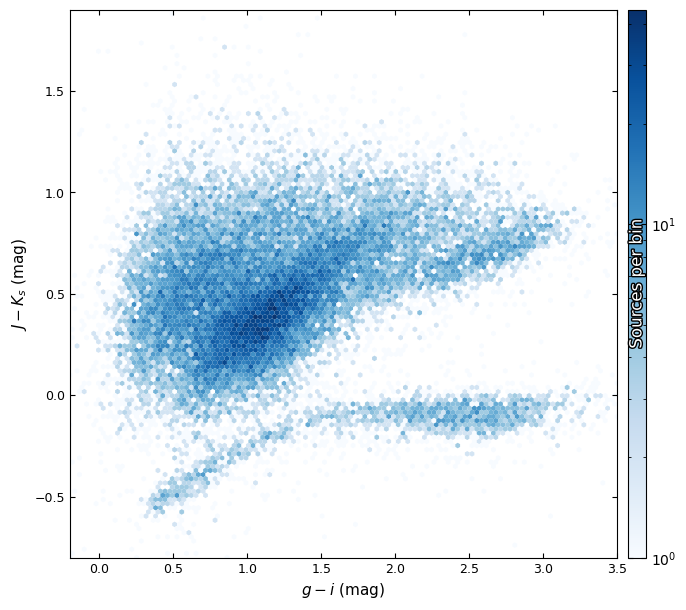


Saved figure to:
data/plots_photometry_corrnoise/dp1_gi_JKs_colour_distribution.pdf


In [17]:
from matplotlib.colors import LogNorm
import matplotlib.patheffects as pe


# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------

SNR_MIN = 5.0

X_LIMITS = (-0.2, 3.5)
Y_LIMITS = (-0.8, 1.9)

HEXBIN_GRIDSIZE = 115

OUTPUT_PATH = (
    OUTDIR / "dp1_gi_JKs_colour_distribution.pdf"
)


# ------------------------------------------------------------------
# Optical--near-infrared colours
# ------------------------------------------------------------------

gi = dp1_colour(
    dp1c,
    "g",
    "i",
)

JKs = dp1_colour(
    dp1c,
    "J",
    "K",
)


# ------------------------------------------------------------------
# Clean primary-source sample
# ------------------------------------------------------------------

primary_col = "VIRCAM_K_m_detect_isPrimary"

primary = np.asarray(
    dp1c[primary_col],
    dtype=bool,
)

mask = primary.copy()

for band in ["g", "i", "J", "K"]:
    mask &= dp1_band_usable(
        dp1c,
        band,
        snr_min=SNR_MIN,
    )

mask &= (
    np.isfinite(gi)
    & np.isfinite(JKs)
    & (gi > X_LIMITS[0])
    & (gi < X_LIMITS[1])
    & (JKs > Y_LIMITS[0])
    & (JKs < Y_LIMITS[1])
)


# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7.2, 6.6),
)

fig.subplots_adjust(
    left=0.12,
    right=0.88,
    bottom=0.14,
    top=0.97,
)

density = ax.hexbin(
    gi[mask],
    JKs[mask],
    gridsize=HEXBIN_GRIDSIZE,
    extent=(
        X_LIMITS[0],
        X_LIMITS[1],
        Y_LIMITS[0],
        Y_LIMITS[1],
    ),
    mincnt=1,
    cmap="Blues",
    norm=LogNorm(vmin=1),
    linewidths=0,
    rasterized=True,
)

ax.set_xlim(*X_LIMITS)
ax.set_ylim(*Y_LIMITS)

ax.set_xlabel(
    r"$g-i$ (mag)",
    fontsize=11,
)

ax.set_ylabel(
    r"$J-K_s$ (mag)",
    fontsize=11,
)

ax.tick_params(
    axis="both",
    direction="in",
    top=True,
    right=True,
    labelsize=9,
)


# ------------------------------------------------------------------
# Colour bar
# ------------------------------------------------------------------

colourbar_axis = fig.add_axes(
    [0.895, 0.14, 0.025, 0.83]
)

colourbar = fig.colorbar(
    density,
    cax=colourbar_axis,
)

colourbar.ax.tick_params(
    which="both",
    direction="in",
    right=True,
    left=True,
)

colourbar.ax.text(
    0.5,
    0.5,
    "Sources per bin",
    transform=colourbar.ax.transAxes,
    rotation=90,
    ha="center",
    va="center",
    color="white",
    fontsize=12,
    path_effects=[
        pe.withStroke(
            linewidth=2,
            foreground="black",
        )
    ],
)


# ------------------------------------------------------------------
# Report and save
# ------------------------------------------------------------------

print(
    "Optical--near-infrared colour distribution"
)

print(
    f"Primary column    : {primary_col}"
)

print(
    f"Forced S/N limit  : {SNR_MIN:.0f}"
)

print(
    f"Clean sources     : {mask.sum():,}"
)

fig.savefig(
    OUTPUT_PATH,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

print(
    f"\nSaved figure to:\n{OUTPUT_PATH}"
)

### Summary of photometric validation

- The VIDEO comparison gives median DP1–VIDEO residuals near **+0.06–0.07 mag**, with robust scatter of **0.08–0.10 mag** for the cleaned near-infrared samples.
- The bright stellar comparison has an NMAD near **0.037 mag** over 16 ≤ Ks < 22; the measured offset varies appreciably with the VIDEO aperture definition.
- Positionally ambiguous matches are common, so the strict closest-association sample is used as a robustness check rather than the default photometric sample.
- The colour–colour diagrams retain coherent population structure under joint per-band S/N and pixel-quality cuts. The publication figure contains **31,423** well-measured primary sources.

These results quantify the photometric performance of the corrected DP1 catalogue. The S/N-selected samples should not be interpreted as the complete source detections or as direct measures of survey completeness.